# 12 – Neptune (stage 11: planets)

**What:** A colour close-up of Neptune and its rings from NIRCam data of programme 2739 (12 July 2022, four medium-band filters F140M, F210M, F300M, F460M).

**Why:** The first planet – and the first **moving target**. Our pipeline so far assumes fixed stars: same sky position = same pixel. Neptune moves across the sky by fractions of an arcsecond during the observation, so the filters have to be aligned on the planet instead. Microscopy analogy: imaging a moving cell – before overlaying channels you need to know whether the stage tracked the cell, and if channels were taken at different times, you register on the cell, not on the coverslip.

**Steps (with checkpoints):**
1. Data
2. Moving target in the header
3. First look
4. Stripes – *checkpoint: is the 2-D background safe for the rings?*
5. Alignment on the planet – close-up grid (14″, 0.031″/px)
6. Bad pixels
7. Background and stretch – *checkpoint: stretch strength*
8. Colour – *checkpoint: variant*
9. Export

**Result:** Two colour close-ups of Neptune and its rings (14″ × 14″, 455 × 455 px at 0.031″/px, north up), in `output/`: **A_chromatic** (hues by wavelength) and **G_white_clouds** (aesthetic choice: pale blue disk, white clouds, bluish rings). The filters, taken in two pairs ≈ 24 min apart, were aligned on the planet using the header's mean target positions (shift 0.62″ ≈ 20 px at 0.031″); disk centres agree to 0.5–0.9 px. All parameters and all tried colour variants in `params/neptune.json`.

## 1. Data

Same as before: find the stage-3 images (`_i2d.fits`) of observation `o004`, download what is missing (files already present are skipped). Programme 2739 also contains other targets, hence the filter on the observation.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import AsinhStretch, PercentileInterval, ImageNormalize
from astropipe import bands, clean, color, export, mast, registration, stretch
from astropipe.run import assess_field

ROOT = Path("..")
RAW = ROOT / "data/neptune_2739_nircam"
WORK = ROOT / "data/neptune_nb"          # intermediate results of this notebook (not in git)
WORK.mkdir(parents=True, exist_ok=True)


def show(ax, img, title="", pct=99.5, a=0.02):
    """Quick-look display: percentile limits + asinh."""
    norm = ImageNormalize(img, interval=PercentileInterval(pct), stretch=AsinhStretch(a))
    ax.imshow(img, origin="lower", cmap="gray", norm=norm)
    ax.set_title(title)
    ax.axis("off")


def cut(img, cy, cx, half):
    """Square cutout of +-half pixels around (cy, cx)."""
    cy, cx = int(round(cy)), int(round(cx))
    return img[max(cy - half, 0):cy + half, max(cx - half, 0):cx + half]


obs, i2d = mast.find_i2d(2739)
i2d = i2d[[n.startswith("jw02739-o004_t003_") for n in i2d["productFilename"]]]
print(len(i2d), f"files, {mast.total_size_gb(i2d):.2f} GB")

DOWNLOAD = True                          # files already present are skipped
if DOWNLOAD:
    mast.download(i2d, RAW, max_gb=3.0)

FILES = {bands.band_from_header(fits.getheader(f, 0)): f for f in sorted(RAW.glob("*_i2d.fits"))}
FILES = {b: FILES[b] for b in bands.sort_bands(FILES)}
FILES

4 files, 1.65 GB
4 of 4 files already present, 0 to download (0.00 GB)


{'F140M': PosixPath('../data/neptune_2739_nircam/jw02739-o004_t003_nircam_clear-f140m_i2d.fits'),
 'F210M': PosixPath('../data/neptune_2739_nircam/jw02739-o004_t003_nircam_clear-f210m_i2d.fits'),
 'F300M': PosixPath('../data/neptune_2739_nircam/jw02739-o004_t003_nircam_clear-f300m_i2d.fits'),
 'F460M': PosixPath('../data/neptune_2739_nircam/jw02739-o004_t003_nircam_clear-f460m_i2d.fits')}

## 2. Moving target in the header

For moving targets the header carries extra keywords. `TARGTYPE = MOVING` marks the target as moving; `MT_AVRA` / `MT_AVDEC` (in the SCI header) are, as I understand it, the target's **mean position during the exposure**.

NIRCam exposes the short- and long-wavelength channel at the same time (dichroic), so the four filters form two pairs. If Neptune moved between the pairs, their `MT_AV` positions differ.

In [2]:
rows = {}
for b, f in FILES.items():
    h0, h1 = fits.getheader(f, 0), fits.getheader(f, extname="SCI")
    rows[b] = dict(start=h0["DATE-BEG"][11:19], end=h0["DATE-END"][11:19], targtype=h0["TARGTYPE"],
                   mt_ra=h1["MT_AVRA"], mt_dec=h1["MT_AVDEC"],
                   pix=float(registration.pixel_scale_arcsec(WCS(h1))[0]))

ref = next(iter(rows))
for b, r in rows.items():
    dra = (r["mt_ra"] - rows[ref]["mt_ra"]) * 3600 * np.cos(np.radians(r["mt_dec"]))
    ddec = (r["mt_dec"] - rows[ref]["mt_dec"]) * 3600
    d = np.hypot(dra, ddec)
    print(f"{b}: {r['start']}-{r['end']} UTC  {r['targtype']}  pixel {r['pix']:.4f}\"  "
          f"planet position vs {ref}: {d:.3f}\" (= {d / 0.063:.1f} px at 0.063\")")

F140M: 06:28:36-07:52:32 UTC  MOVING  pixel 0.0308"  planet position vs F140M: 0.000" (= 0.0 px at 0.063")
F210M: 06:52:46-08:33:41 UTC  MOVING  pixel 0.0308"  planet position vs F140M: 0.622" (= 9.9 px at 0.063")
F300M: 06:28:36-07:52:32 UTC  MOVING  pixel 0.0630"  planet position vs F140M: 0.000" (= 0.0 px at 0.063")
F460M: 06:52:46-08:33:41 UTC  MOVING  pixel 0.0630"  planet position vs F140M: 0.622" (= 9.9 px at 0.063")


## 3. First look

Each filter in its own pixel grid, centred on Neptune's disk. Top: a 40″ field (rings, Triton, background). Bottom: 8″ around the planet with a strong stretch, to see the rings.

**Things to look at:** Is Neptune sharp? Are background stars points or short trails (the pipeline followed the planet)? How different does Neptune look in the four filters (methane absorption)?

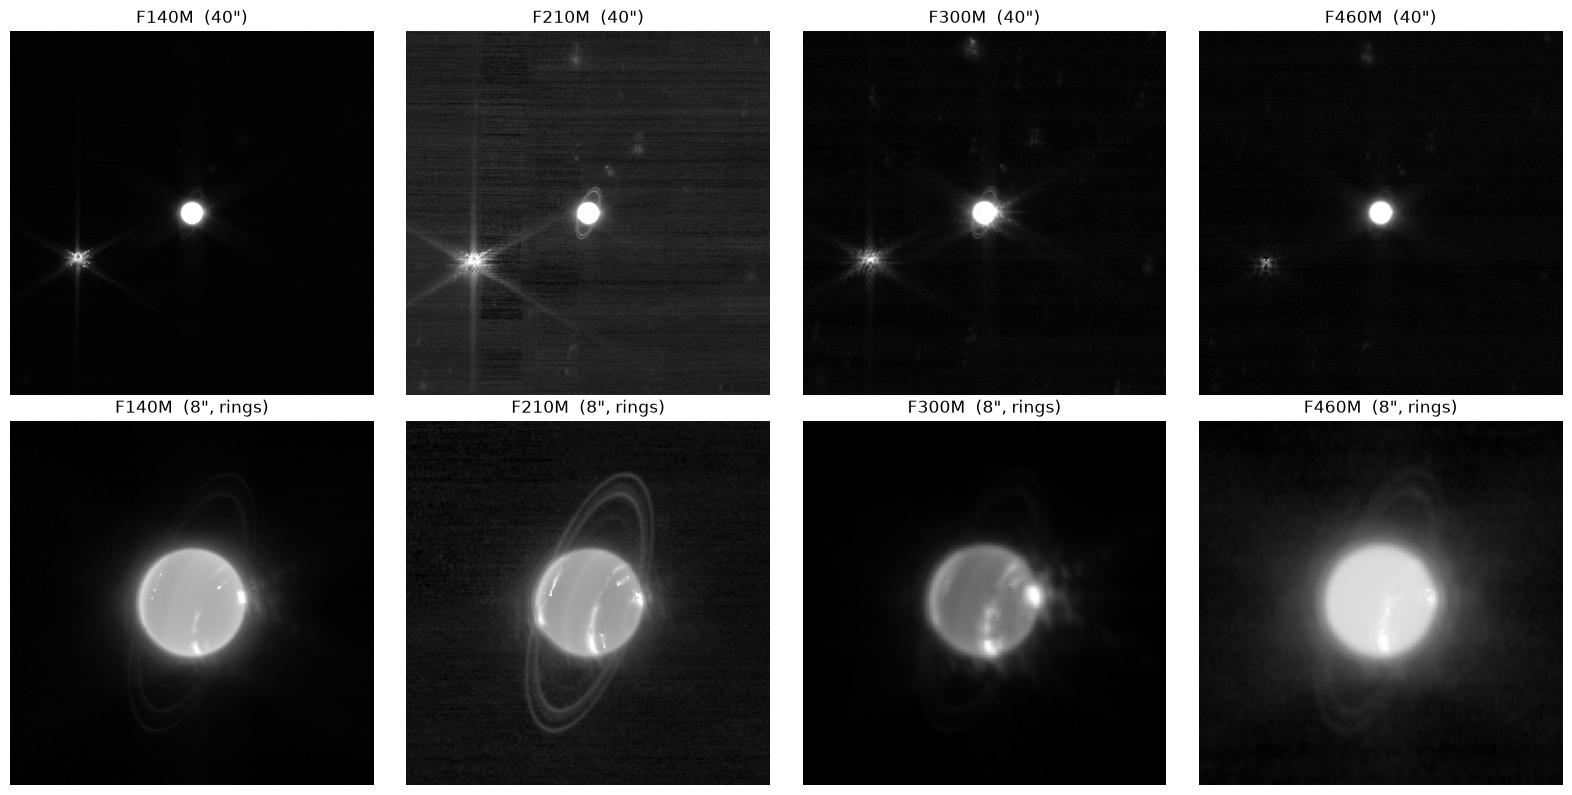

In [3]:
raw = {b: fits.getdata(f, extname="SCI").astype(np.float32) for b, f in FILES.items()}
pix = {b: rows[b]["pix"] for b in raw}
cen_raw = {b: registration.disk_centroid(img) for b, img in raw.items()}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, b in enumerate(raw):
    cy, cx = cen_raw[b]
    show(axes[0, i], cut(raw[b], cy, cx, int(20 / pix[b])), f"{b}  (40\")")
    show(axes[1, i], cut(raw[b], cy, cx, int(4 / pix[b])), f"{b}  (8\", rings)", pct=99.9, a=0.005)
plt.tight_layout()

## 4. Stripes

**Measurement:** the same automatic check as in the explorer (`clean.method = "auto"`): large-scale structure relative to the sky noise (decides "empty field" vs. "object fills the field") and stripe strength along rows and columns.

**Correction candidates** (on F210M, which showed the strongest stripes):
- row profile from the empty sky **without** high-pass (`smooth = 0`), in 512-px segments – removes broad bands too (as for the deep field J0217);
- in addition a **2-D background** (median in 128-px cells, sources masked) – removes steps between detectors/exposures, **but** it could also remove faint emission larger than a few arcseconds. Neptune's rings are faint and extend to roughly 2–3 planet radii, so this has to be checked.

The bottom row shows what each step **removed**. It must contain stripes and smooth steps only – no rings.

In [4]:
field = assess_field(FILES)
print("empty field:", field["empty_field"])

[17:48:24] field type: empty (compact sources)
[17:48:24] F140M: structure 1.1 sigma, sky 0.60, stripes rows 0.45 / columns 0.32 -> sky (rows), 2-D bg 128
[17:48:24] F210M: structure 1.2 sigma, sky 0.57, stripes rows 0.46 / columns 0.31 -> sky (rows), 2-D bg 128
[17:48:24] F300M: structure 1.1 sigma, sky 0.48, stripes rows 0.47 / columns 0.26 -> sky (rows), 2-D bg 128
[17:48:24] F460M: structure 1.1 sigma, sky 0.47, stripes rows 0.48 / columns 0.24 -> sky (rows), 2-D bg 128
empty field: True


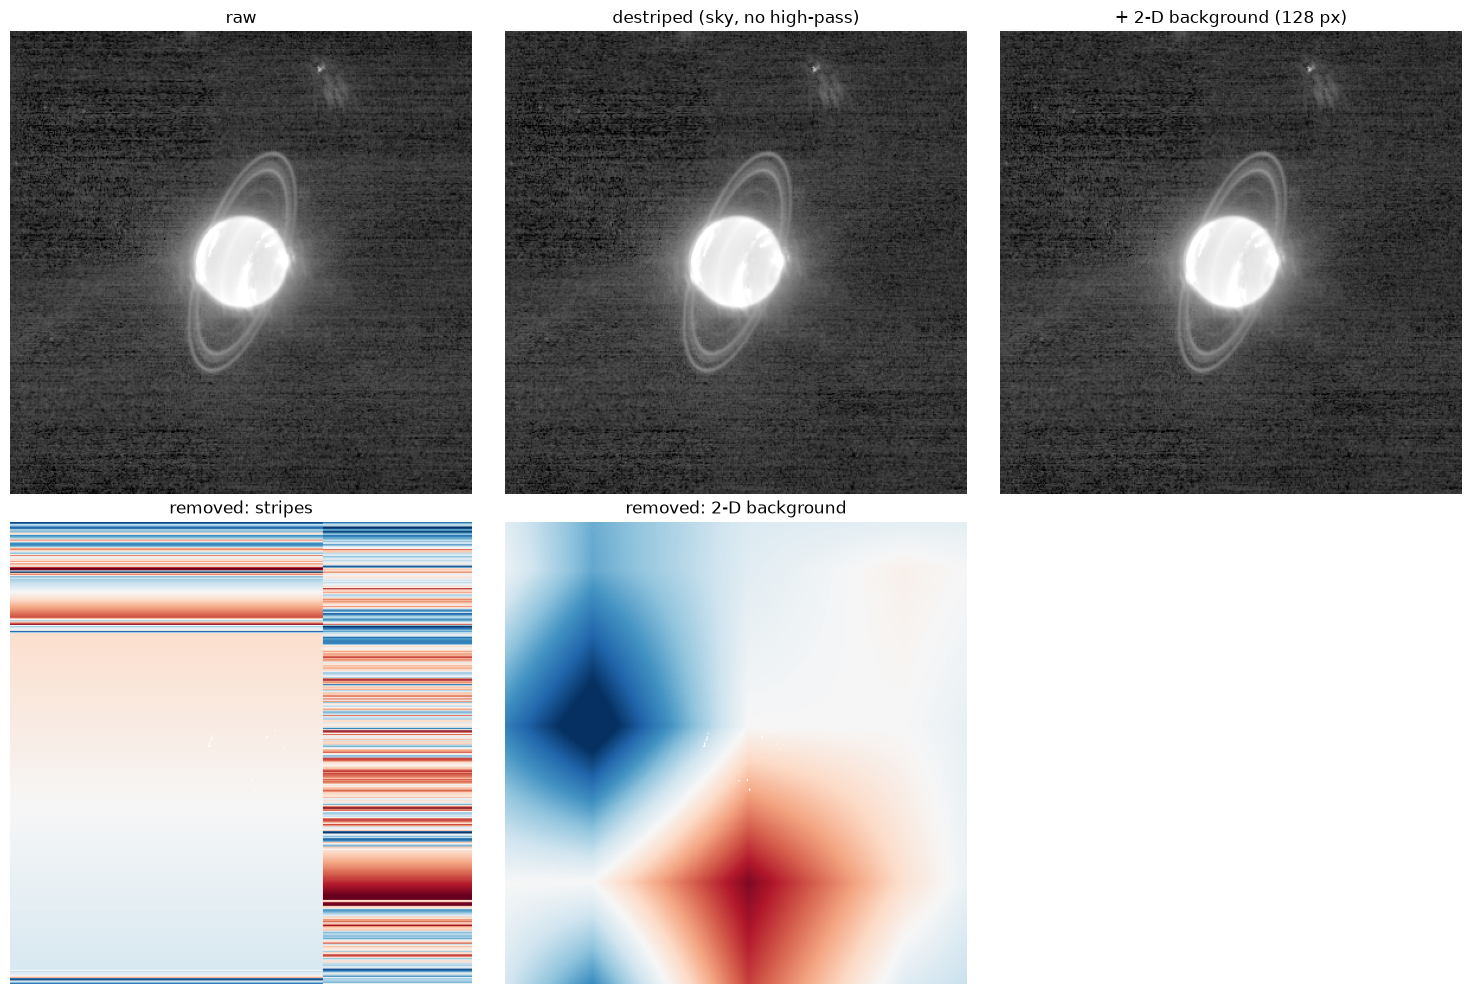

In [5]:
B = "F210M"
img = raw[B]
sky, _, _ = clean.destripe(img, "rows", smooth=0, segment=512)
sky_bg, model = clean.subtract_background_2d(sky, cell=128)

cy, cx = cen_raw[B]
h = int(6 / pix[B])                      # +-6" around Neptune
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, im, t in zip(axes[0], [img, sky, sky_bg],
                     ["raw", "destriped (sky, no high-pass)", "+ 2-D background (128 px)"]):
    show(ax, cut(im, cy, cx, h), t, pct=99.0, a=0.005)
for ax, im, t in zip(axes[1], [img - sky, sky - sky_bg], ["removed: stripes", "removed: 2-D background"]):
    c = cut(im, cy, cx, h)
    s = np.nanpercentile(np.abs(c), 99)
    ax.imshow(c, origin="lower", cmap="RdBu_r", vmin=-s, vmax=s)
    ax.set_title(t)
    ax.axis("off")
axes[1, 2].axis("off")
plt.tight_layout()

**Checkpoint:** Do the rings appear in "removed: 2-D background"? If yes → `USE_BG2D = False`. Then apply the chosen correction to all four filters (written to `data/neptune_nb/cleaned/`).

In [6]:
USE_BG2D = True        # set to False if the 2-D background removes part of the rings

cleaned = {}
for b, f in FILES.items():
    out, _, _ = clean.destripe(raw[b], "rows", smooth=0, segment=512)
    if USE_BG2D:
        out, _ = clean.subtract_background_2d(out, cell=128)
    dest = WORK / "cleaned" / f.name.replace("_i2d", "_clean_i2d")
    clean.write_cleaned_i2d(f, dest, out, f"12_neptune: destripe sky smooth=0 segment=512, bg2d={USE_BG2D}")
    cleaned[b] = dest
    print(b, "->", dest.name)

F140M -> jw02739-o004_t003_nircam_clear-f140m_clean_i2d.fits
F210M -> jw02739-o004_t003_nircam_clear-f210m_clean_i2d.fits
F300M -> jw02739-o004_t003_nircam_clear-f300m_clean_i2d.fits
F460M -> jw02739-o004_t003_nircam_clear-f460m_clean_i2d.fits


## 5. Alignment on the planet – close-up grid

**Decision after step 3:** only the planet and its rings, as a close-up (≈ 14″ × 14″). Triton (≈ 9″ away) stays outside, the outer bright rings (≈ 3″ from the centre) and empty sky in the corners stay inside.

**Grid:** north up, centred on Neptune, at the **short-wavelength pixel scale (≈ 0.031″)** instead of 0.063″, so the rings in F140M/F210M keep their full sharpness. F300M/F460M (0.063″) are **upsampled** by a factor of 2 – this creates no new detail (same honest note as for MIRI in notebook 09a).

**Alignment:** each image's WCS is shifted by the difference of the `MT_AV` positions (step 2), so that Neptune has the same sky coordinates in all filters; the grid is centred on that position.

In [7]:
offs = registration.moving_target_offsets(cleaned)
shifted = {}
for b, f in cleaned.items():
    dra, ddec = offs[b]
    shifted[b] = registration.write_shifted_i2d(f, WORK / "mt" / f.name.replace(".fits", "_mt.fits"), dra, ddec)
    print(f"{b}: WCS shifted by ({dra * 3600:+.3f}\", {ddec * 3600:+.3f}\") in (RA, Dec)")

F140M: WCS shifted by (+0.000", +0.000") in (RA, Dec)
F210M: WCS shifted by (+0.543", +0.303") in (RA, Dec)
F300M: WCS shifted by (+0.000", +0.000") in (RA, Dec)
F460M: WCS shifted by (+0.543", +0.303") in (RA, Dec)


In [8]:
FIELD_ARCSEC = 14.0
RES = pix["F140M"]                         # short-wavelength pixel scale, ≈ 0.031"
ra0, dec0 = rows[ref]["mt_ra"], rows[ref]["mt_dec"]   # Neptune's mean position (reference after the shift)

n = int(round(FIELD_ARCSEC / RES))
wcs_out = WCS(naxis=2)
wcs_out.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs_out.wcs.crval = [ra0, dec0]
wcs_out.wcs.crpix = [(n + 1) / 2, (n + 1) / 2]
wcs_out.wcs.cdelt = [-RES / 3600, RES / 3600]     # RA increases to the left: north up, east left
shape_out = (n, n)

reproj = registration.reproject_all(shifted, wcs_out, shape_out, WORK / "reproj_zoom", "neptune_zoom")
imgs = {b: fits.getdata(p).astype(np.float32) for b, p in reproj.items()}
print("grid", shape_out, f"at {RES:.4f}\"/px")

F140M   outdated (made from jw02739-o004_t003_nircam_clear-f140m_clean_i2d_mt.fits) -> reprojecting
F140M      0.3 s -> neptune_zoom_f140m_reproj.fits
F210M   outdated (made from jw02739-o004_t003_nircam_clear-f210m_clean_i2d_mt.fits) -> reprojecting
F210M      0.3 s -> neptune_zoom_f210m_reproj.fits
F300M   outdated (made from jw02739-o004_t003_nircam_clear-f300m_clean_i2d_mt.fits) -> reprojecting
F300M      0.3 s -> neptune_zoom_f300m_reproj.fits
F460M   outdated (made from jw02739-o004_t003_nircam_clear-f460m_clean_i2d_mt.fits) -> reprojecting
F460M      0.3 s -> neptune_zoom_f460m_reproj.fits
grid (455, 455) at 0.0308"/px


**Check:** the geometric centre of Neptune's disk (unweighted, so bright clouds do not pull it) in every filter – it should sit close to the grid centre and agree between the filters to well below 1 px. The overlay F140M (magenta) / F460M (green) – the two filters taken at *different* times – should show the disk without one-sided fringes. A symmetric green rim is expected: F460M is less sharp (diffraction limit ∝ wavelength).

grid centre (227.0, 227.0)
F140M: disk centre (227.2, 225.1), offset vs F460M 0.48 px
F210M: disk centre (227.6, 225.2), offset vs F460M 0.94 px
F300M: disk centre (226.3, 224.7), offset vs F460M 0.51 px
F460M: disk centre (226.8, 224.8), offset vs F460M 0.00 px


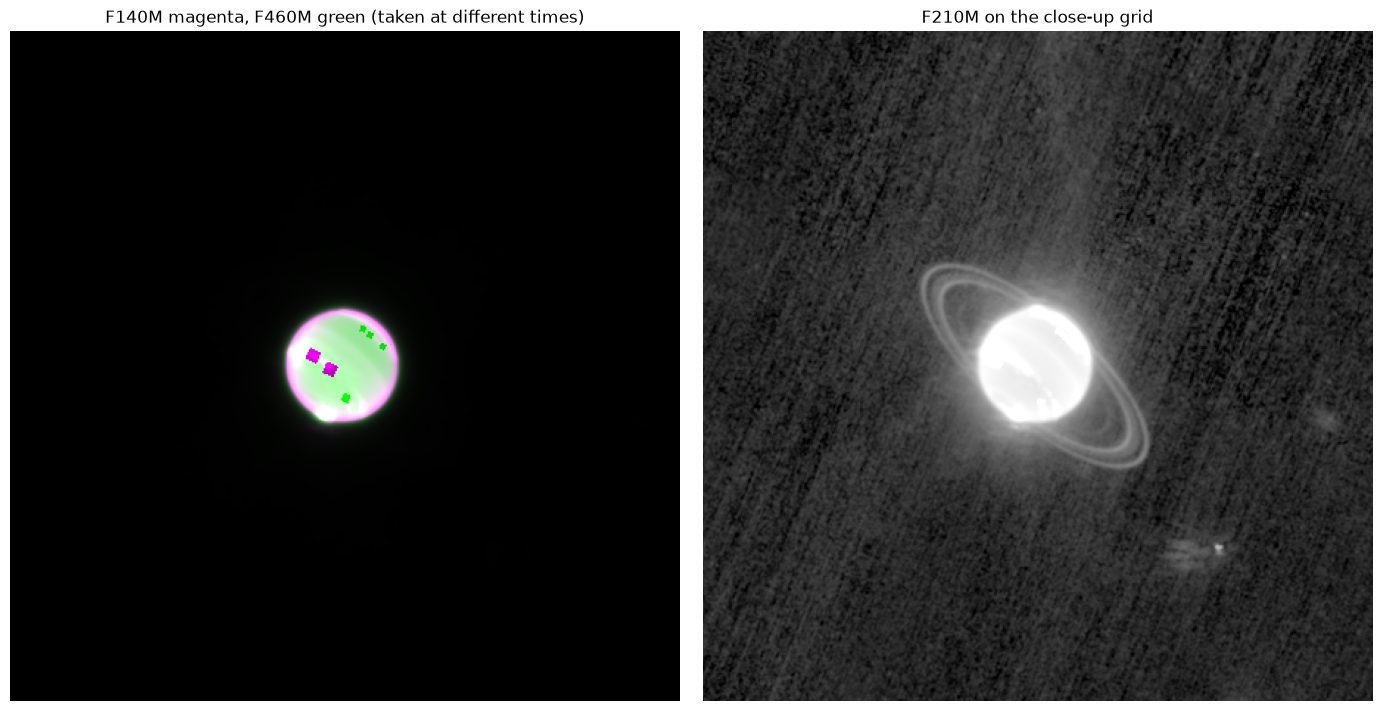

In [9]:
ref_disk = registration.disk_mask(imgs["F460M"])      # F460M: smooth disk, no rings
cen = {b: registration.disk_centroid(im, ref_mask=ref_disk) for b, im in imgs.items()}
y0, x0 = cen["F460M"]
print(f"grid centre ({(n - 1) / 2:.1f}, {(n - 1) / 2:.1f})")
for b, (y, x) in cen.items():
    print(f"{b}: disk centre ({y:.1f}, {x:.1f}), offset vs F460M {np.hypot(y - y0, x - x0):.2f} px")


def norm01(c, pct=99.5):
    c = np.nan_to_num(c)
    lo, hi = np.percentile(c, [1, pct])
    return np.clip((c - lo) / (hi - lo), 0, 1)


m, g = norm01(imgs["F140M"]), norm01(imgs["F460M"])
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(np.dstack([m, g, m]), origin="lower")
axes[0].set_title("F140M magenta, F460M green (taken at different times)")
show(axes[1], imgs["F210M"], "F210M on the close-up grid", pct=99.0, a=0.005)
axes[0].axis("off")
plt.tight_layout()

## 6. Bad pixels and saturated clouds

With Triton outside the field, the remaining NaN holes are bad/flagged pixels (filled with the median of their surroundings, see notebook 10) – and a few **saturated cores of very bright clouds** (in F210M). For those, the global image maximum (used for star cores) would make a white spot in one filter only and a wrongly coloured pixel in the colour image. Here they get the **maximum of their immediate surroundings** (`sat_fill="local"`).

`UNIFY_SATURATED`: a pixel saturated in any filter becomes white in all filters after stretching (cosmetic; bright clouds are white in the chosen colour variant anyway).

In [10]:
UNIFY_SATURATED = True

filled, sat_union = {}, np.zeros(next(iter(imgs.values())).shape, bool)
for b, im in imgs.items():
    lab, holes = stretch.classify_holes(im)
    for hh in holes:
        if hh["saturated"]:
            sat_union |= lab == hh["label"]
    filled[b], n_sat, n_bad = stretch.fill_holes(im, sat_fill="local")
    print(f"{b}: saturated {n_sat} px, bad pixels {n_bad} px, NaN left {int(np.isnan(filled[b]).sum())}")
print("saturated in at least one filter:", int(sat_union.sum()), "px")

F140M: saturated 0 px, bad pixels 78 px, NaN left 0
F210M: saturated 47 px, bad pixels 147 px, NaN left 0
F300M: saturated 0 px, bad pixels 0 px, NaN left 0
F460M: saturated 0 px, bad pixels 134 px, NaN left 0
saturated in at least one filter: 47 px


## 7. Background and stretch

Background and noise from small empty boxes in the corners of the close-up (the 2-D background in step 4 has already flattened the sky). **White point from the disk** instead of a field percentile: 99.5 % of the disk pixels → the disk is well exposed, the brightest clouds may burn out slightly.

The comparison shows F210M with different asinh strengths `a`: smaller `a` = stronger stretch → the faint rings come up, but so does the noise.

In [11]:
valid = stretch.common_valid(filled)
boxes, scores = stretch.find_sky_boxes(filled, valid, box=50, edge_margin=10, n_boxes=4, min_sep=150)
# no "score > 0" rule here: after the 2-D background the empty sky is ~0, half of the boxes
# would have slightly negative medians and be dropped for no reason
stats = stretch.sky_stats(filled, boxes, 50)
disk = registration.disk_mask(filled["F460M"])
print(len(boxes), "sky boxes:", boxes, "  Neptune's disk:", int(disk.sum()), "px")
for b in filled:
    x = filled[b] - stats[b]["bkg"]
    print(f"{b}: bkg {stats[b]['bkg']:.4f}  noise {stats[b]['noise']:.4f}  "
          f"white from disk (99.5 %) {np.percentile(x[disk & valid], 99.5):.3f}")

4 sky boxes: [(375, 50), (200, 0), (0, 150), (250, 400)]   Neptune's disk: 4215 px
F140M: bkg 0.2021  noise 0.0441  white from disk (99.5 %) 1254.858
F210M: bkg 0.1143  noise 0.0337  white from disk (99.5 %) 137.208
F300M: bkg 0.1171  noise 0.0069  white from disk (99.5 %) 439.221
F460M: bkg 0.3483  noise 0.0137  white from disk (99.5 %) 90.245


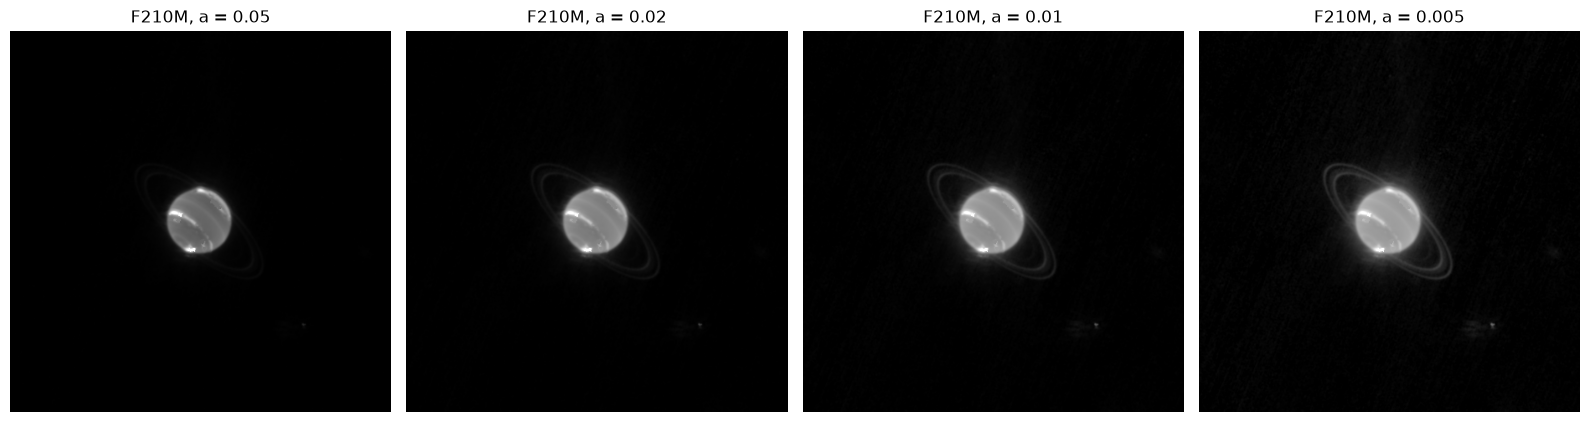

In [12]:
B, A_VALUES = "F210M", [0.05, 0.02, 0.01, 0.005]
white = float(np.percentile((filled[B] - stats[B]["bkg"])[disk & valid], 99.5))
y, _, _ = stretch.normalize(filled[B], valid, stats[B]["bkg"], stats[B]["noise"], 0.5, 99.9, white)
fig, axes = plt.subplots(1, len(A_VALUES), figsize=(16, 4.5))
for ax, a in zip(axes, A_VALUES):
    ax.imshow(stretch.asinh_stretch(y, a), origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{B}, a = {a}")
    ax.axis("off")
plt.tight_layout()

**Checkpoint:** choose `A_VALUE` (rings visible, noise acceptable). `BLACK_K` as before: larger → brighter, noisier background; negative → noise turns black.

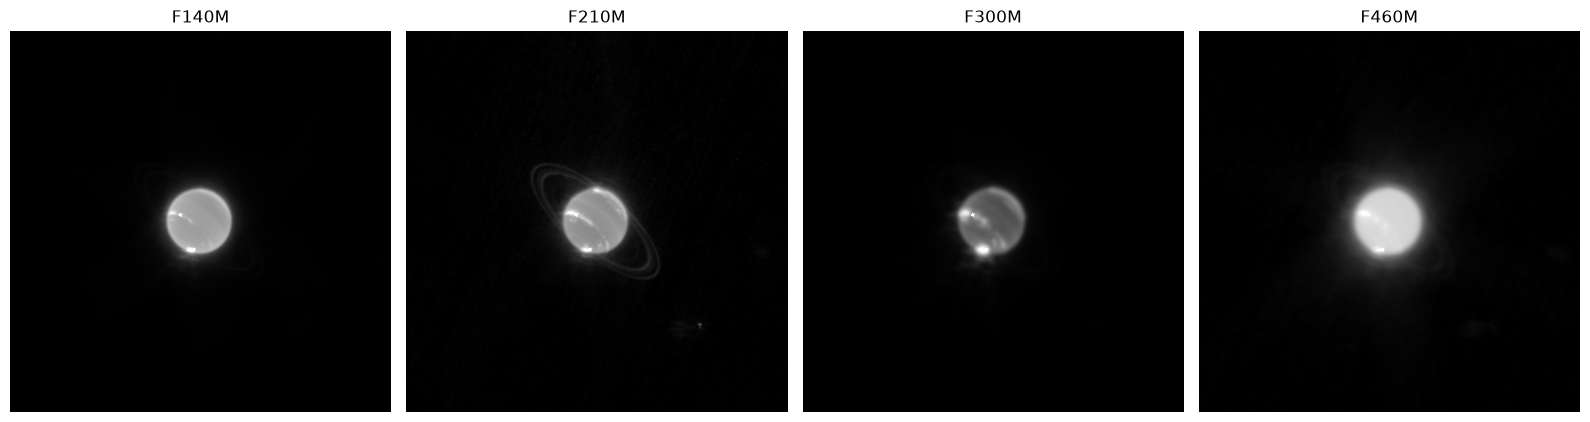

In [13]:
A_VALUE, BLACK_K, WHITE_PCT_DISK = 0.01, 0.5, 99.5

params = {}
for b in filled:
    x = filled[b] - stats[b]["bkg"]
    params[b] = dict(black_k=BLACK_K, white_pct=99.9, a=A_VALUE,
                     white_value=float(np.percentile(x[disk & valid], WHITE_PCT_DISK)))
stretched, levels = stretch.stretch_all(filled, valid, stats, params)
if UNIFY_SATURATED:
    for b in stretched:
        stretched[b][sat_union] = 1.0

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, b in zip(axes, stretched):
    ax.imshow(stretched[b], origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(b)
    ax.axis("off")
plt.tight_layout()

## 8. Colour

**What we learned while trying variants:** after stretching, Neptune's disk is similarly bright in all four filters (disk median ≈ 0.4–0.8). Additive mixing then turns the disk into the **average of the four hues** – any palette made only of blue/cyan hues ends up as nearly uniform cyan, however the angles are spread (B, C, E). Differences only show where the filters differ: clouds, rings, limb. A hue with red in it on F460M (the brightest disk) tints the whole disk pink (D).

The useful lever is what *distinguishes* the filters: **F300M** has a comparatively dark disk but very bright clouds. Given **no colour** (grey) it turns the clouds white while the other three filters keep the disk blue (G). Luminance (LRGB, as in notebook 09a): part of the brightness from F210M, the sharpest filter with the clearest rings.

| Variant | Idea | Result |
|---|---|---|
| A_chromatic | hues by wavelength, no luminance layer | chromatic ("scientific" order); pink-lavender disk |
| B_blue | cool hues 170–230° | nearly uniform cyan |
| C_blue_lrgb | B + 50 % luminance from F210M | sharper, still cyan |
| D_cool_wide | 150–270° + luminance | F460M violet → pink disk |
| E_cool | 155–240° + luminance | again nearly uniform cyan |
| **G_white_clouds** | F300M grey, others blue/cyan + 50 % luminance F210M | pale blue disk, white clouds, bluish rings – **chosen** |
| G2_rings | G + F210M weight 2, luminance stretched more (a = 0.005) | brighter rings, but more halo and noise |

All variants except A are **chosen freely** (inspired by Neptune's familiar look in visible light) – the light is infrared, every colour is an assignment.

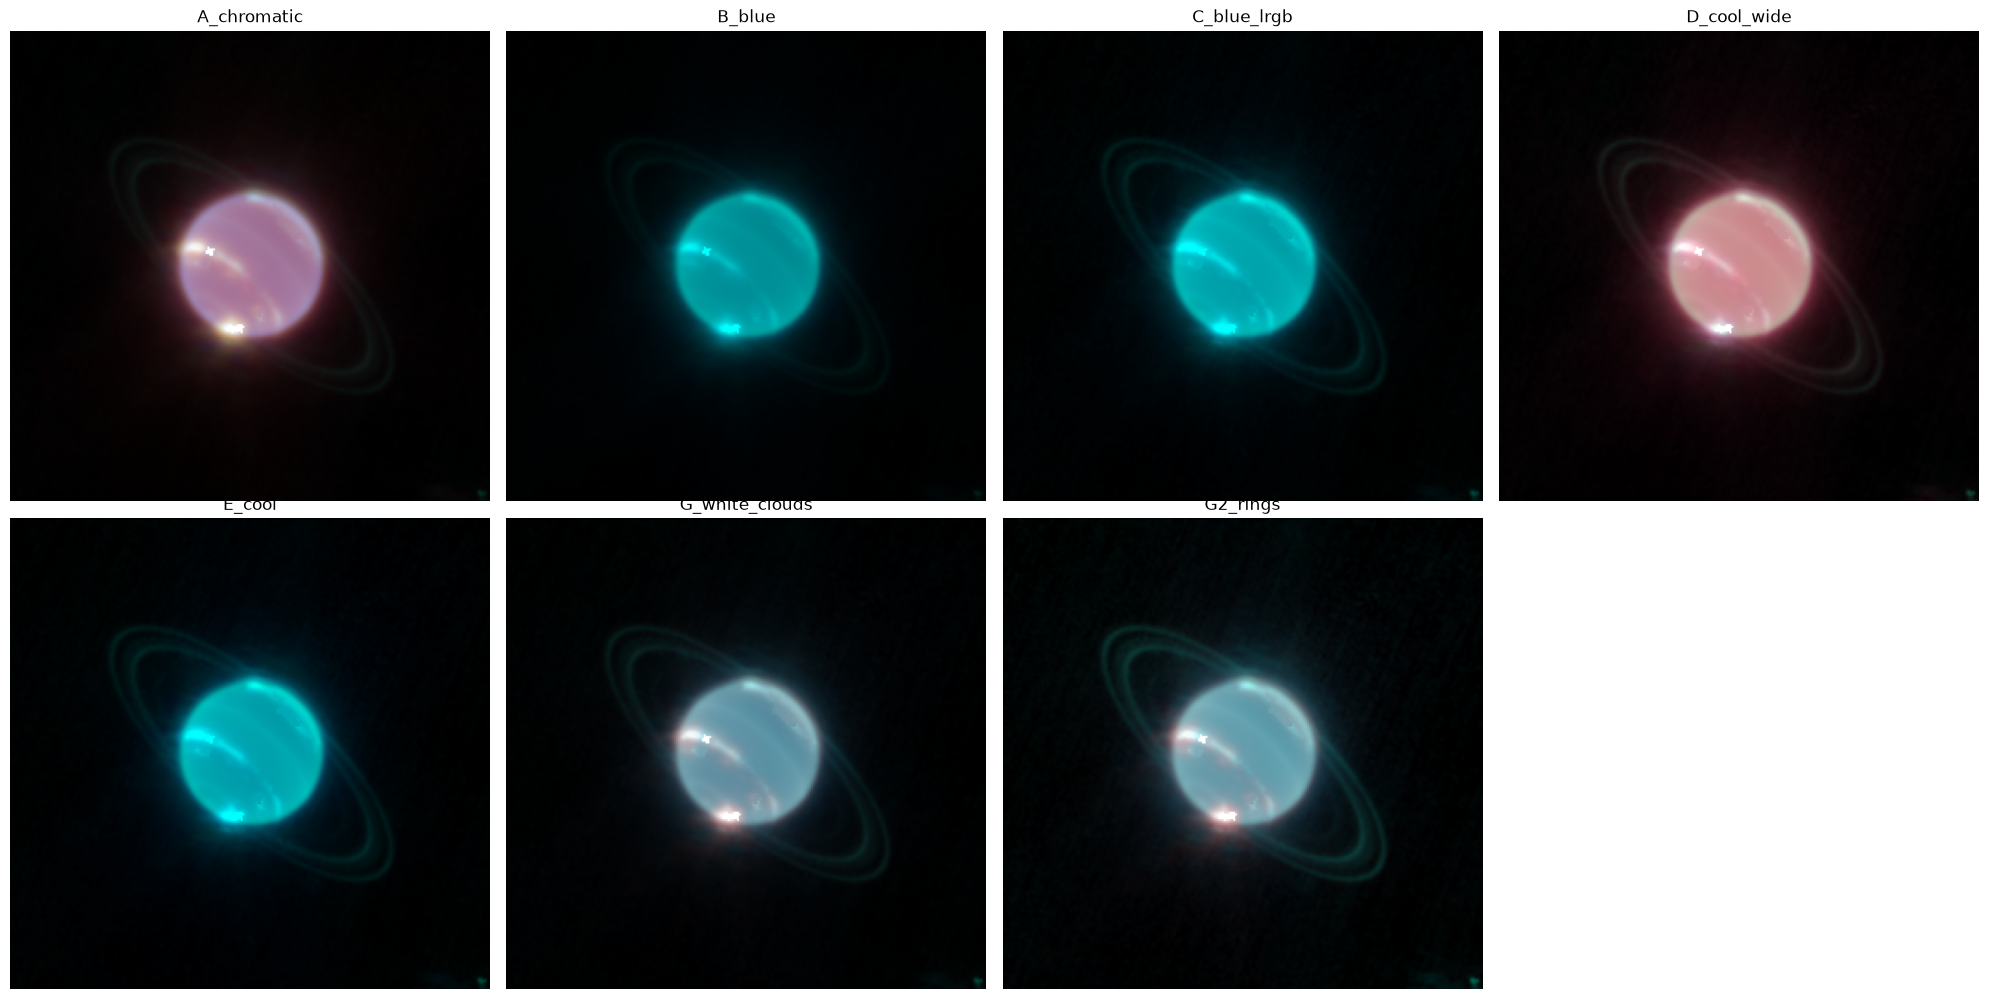

In [14]:
chromatic = {b: 240 - i * 240 / (len(stretched) - 1) for i, b in enumerate(stretched)}
y_lum, _, _ = stretch.normalize(filled["F210M"], valid, stats["F210M"]["bkg"], stats["F210M"]["noise"],
                                BLACK_K, 99.9, params["F210M"]["white_value"])
LUM = {"F210M": stretched["F210M"], "F210M_a0.005": stretch.asinh_stretch(y_lum, 0.005)}

VARIANTS = {
    "A_chromatic": dict(hues=chromatic, label="hues by wavelength (chromatic), F140M blue to F460M red"),
    "B_blue": dict(hues={"F140M": 170, "F210M": 190, "F300M": 210, "F460M": 230},
                   label="chosen freely: cool hues"),
    "C_blue_lrgb": dict(hues={"F140M": 170, "F210M": 190, "F300M": 210, "F460M": 230}, lum=("F210M", 0.5),
                        label="chosen freely: cool hues, 50 % luminance from F210M"),
    "D_cool_wide": dict(hues={"F140M": 150, "F210M": 190, "F300M": 230, "F460M": 270}, lum=("F210M", 0.5),
                        label="chosen freely: wide cool hues, 50 % luminance from F210M"),
    "E_cool": dict(hues={"F140M": 155, "F210M": 185, "F300M": 215, "F460M": 240}, lum=("F210M", 0.5),
                   label="chosen freely: cool hues without red, 50 % luminance from F210M"),
    "G_white_clouds": dict(hues={"F140M": 200, "F210M": 180, "F300M": 0, "F460M": 225}, sat={"F300M": 0.0},
                           lum=("F210M", 0.5),
                           label="chosen freely, inspired by Neptune's visible-light colour: F300M without colour "
                                 "(bright clouds white), 50 % luminance from F210M"),
    "G2_rings": dict(hues={"F140M": 200, "F210M": 180, "F300M": 0, "F460M": 225}, sat={"F300M": 0.0},
                     weights={"F210M": 2.0}, lum=("F210M_a0.005", 0.6),
                     label="as G, F210M weight 2, 60 % luminance from F210M stretched with a = 0.005"),
}


def make_rgb(v):
    rgb = color.compose(stretched, color.mapping_from_degrees(v["hues"], v.get("sat", {})), v.get("weights", {}))
    if "lum" in v:
        rgb = color.apply_luminance(rgb, LUM[v["lum"][0]], v["lum"][1])
    return rgb


rgbs = {k: make_rgb(v) for k, v in VARIANTS.items()}
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, (k, rgb) in zip(axes.flat, rgbs.items()):
    ax.imshow(rgb[100:355, 95:355], origin="lower")
    ax.set_title(k)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()

## 9. Export

Two versions are exported: **A_chromatic** (colours in wavelength order) and **G_white_clouds** (aesthetic choice). The whole close-up, no further crop. Orientation check via WCS; TIFF/PNG full resolution in `output/full_res/`, web JPEG + caption in `output/`. All parameters (including all tried variants) go to `params/neptune.json`.

In [15]:
EXPORT = ["A_chromatic", "G_white_clouds"]

north_up, east_left = export.orientation(wcs_out, n // 2, n // 2)
print("north up:", north_up, "  east left:", east_left)


def caption_for(name):
    v = VARIANTS[name]
    table = "\n".join(f"| {b} | {v['hues'][b]:.0f}°" + (" (no colour)" if v.get("sat", {}).get(b) == 0 else "")
                       + " |" for b in v["hues"])
    steps = ["calibrated stage-3 images (`_i2d.fits`) from MAST",
             "row destriping on empty sky (no high-pass)" + (" + 2-D background (128 px)" if USE_BG2D else ""),
             "aligned on the planet (WCS shifted by the target's mean positions, header MT_AVRA/MT_AVDEC)",
             f"close-up grid {RES:.3f}″/px centred on Neptune (`reproject_adaptive`; F300M/F460M upsampled ×2)",
             "background from empty corners",
             f"asinh stretch (a = {A_VALUE}), white point from Neptune's disk ({WHITE_PCT_DISK} %), "
             "each filter normalised to its own white point",
             "additive colour mixing" + (f", {int(v['lum'][1] * 100)} % of the brightness from F210M (LRGB)"
                                          if "lum" in v else ""),
             "bad pixels filled with the local median, saturated cloud cores with the local maximum"
             + (", white in all filters where saturated in any" if UNIFY_SATURATED else "") + "; no local adjustments"]
    return f"""# Neptune – JWST NIRCam

Neptune and its rings, observed on 12 July 2022 with NIRCam on the James Webb Space Telescope (programme 2739). Field of view ≈ {FIELD_ARCSEC:.0f}″ × {FIELD_ARCSEC:.0f}″, {"north up, east left" if (north_up and east_left) else "ORIENTATION TO BE CHECKED"}. The filters were taken in two pairs at slightly different times; the images were aligned on the planet.

## Colour assignment ({name}: {v['label']})

| Filter | Hue |
|---|---|
{table}

The recorded light is infrared; all colours are an assignment, not "true" colours.

## Processing

{" → ".join(steps)}. Notebook `12_neptune.ipynb`; all values in `params/neptune.json`.

## Credits

Data: NASA, ESA, CSA, STScI (programme 2739), retrieved via MAST. Processing: Tritium13.
"""


paths = {}
for name in EXPORT:
    paths[name] = export.save_outputs(rgbs[name], caption_for(name), f"neptune_{name}",
                                      ROOT / "output/full_res", ROOT / "output")
    print(name, "->", [p.name for p in paths[name]])

json.dump({"files": {b: f.name for b, f in FILES.items()},
           "moving_target_shift_arcsec": {b: [o[0] * 3600, o[1] * 3600] for b, o in offs.items()},
           "grid": {"centre_radec": [ra0, dec0], "pixel_arcsec": RES, "size_px": n},
           "disk_centre_yx": {b: list(c) for b, c in cen.items()}, "use_bg2d": USE_BG2D,
           "unify_saturated": UNIFY_SATURATED, "sky_boxes": [list(map(int, bx)) for bx in boxes],
           "stretch": {b: {**params[b], **stats[b], **levels[b]} for b in params},
           "colour_variants": VARIANTS, "exported": EXPORT},
          open(ROOT / "params/neptune.json", "w"), indent=2, default=float)

north up: True   east left: True
A_chromatic -> ['neptune_A_chromatic_16bit.tif', 'neptune_A_chromatic_full.png', 'neptune_A_chromatic_web.jpg', 'neptune_A_chromatic_caption.md']
G_white_clouds -> ['neptune_G_white_clouds_16bit.tif', 'neptune_G_white_clouds_full.png', 'neptune_G_white_clouds_web.jpg', 'neptune_G_white_clouds_caption.md']


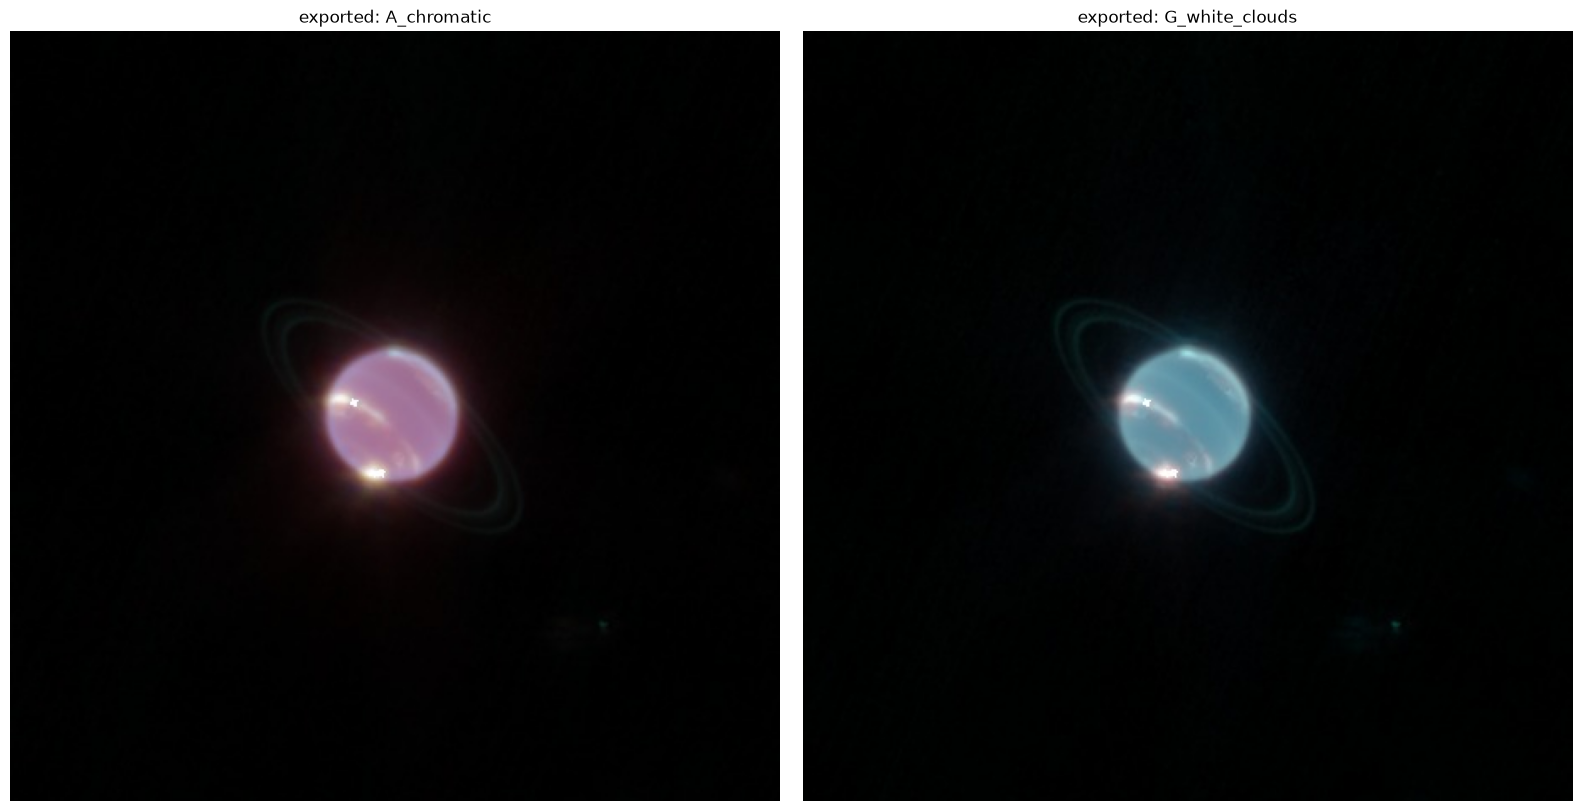

In [16]:
from PIL import Image
fig, axes = plt.subplots(1, len(EXPORT), figsize=(8 * len(EXPORT), 8))
for ax, name in zip(np.atleast_1d(axes), EXPORT):
    ax.imshow(Image.open(paths[name][2]))
    ax.set_title(f"exported: {name}")
    ax.axis("off")
plt.tight_layout()

## Conclusion

- **Moving target:** `TARGTYPE = MOVING`; the JWST pipeline resamples each i2d in the frame of the planet (planet sharp, background stars short trails). Between the two filter pairs Neptune moved by 0.62″. Shifting each WCS by the difference of `MT_AVRA`/`MT_AVDEC` aligns the planet in all filters (disk centres within 0.5–0.9 px; F140M and F300M, taken simultaneously, differ by ≈ 1 px, which shows the measurement precision). Background stars then appear twice – the expected price.
- **Disk centre measurement:** an intensity-weighted centroid is pulled by bright clouds, and a low threshold merges the rings with the disk. Robust: threshold at half the median of each filter inside the F460M disk (smooth disk, no rings), unweighted centre.
- **Close-up instead of the whole field:** 14″ around Neptune at the short-wavelength pixel scale (0.031″) keeps the ring detail of F140M/F210M; F300M/F460M are upsampled ×2 (no new detail). Triton (≈ 9″ away, saturated) stays outside.
- **Stripes:** row destriping helps little around Neptune (offset single exposures in the i2d); the 2-D background (128 px) does not touch the rings. Residual stripes are visible in F210M at strong stretch.
- **Stretch:** white point from the disk (99.5 %) instead of the field; asinh a = 0.01 as compromise – a = 0.05 sharpest surface but no rings, a = 0.005 strong rings but a visible halo (PSF wings around the bright disk).
- **Saturated clouds:** bright clouds saturate in F210M (47 px). Filling with the global maximum (right for star cores) created wrongly coloured pixels → fill with the local maximum, and white in all filters where saturated in any.
- **Colour:** the disk is similarly bright in all four filters, so any palette of blue/cyan hues mixes to a uniform cyan (variants B, C, E); a red-containing hue on F460M tints the disk pink (D). The useful lever is what distinguishes the filters: F300M without colour turns the bright clouds white (G). LRGB with 50 % from F210M brings back the rings; a stronger luminance stretch (G2) gives brighter rings but more halo – G chosen.
- **Open:** transfer the settings to `configs/neptune.toml` (`run.py`); possibly Uranus (programme 6379, 8 filters) next.